# 6. Style Trend Forecast

Forecast of the 10 styles with the highest growth in Works next year, with expected Works and a range for each. The notebook records the whole forecast in project order (question, code, result, interpretation, decision) on saved files and the style by year series. All logic lives in `src/style_series.py`, `src/style_forecast.py`, `src/tuning.py` and `src/style_report.py`, and the cells only import and call it. Target years 1993 to 2017 are the development years, 2018 to 2022 the final test years, and the counts are Works catalogued in Discogs.

## 1. Question and data

### Question: what is forecast, from which series, and what do the counts measure?

The goal is to forecast the 10 styles with the highest growth in Works next year, the expected Works of each with a range, and to let a demo query the models for chosen styles. A Work counts once in each of its styles. The counts are Works catalogued in Discogs, so they depend on what the community has entered, and are not sales, listens or real-world output. The growth of target year t+1 is the count of t+1 over the mean of the counts of t, t-1 and t-2, minus 1. A style is eligible when that three-year mean is at least 100 (a convention). The last reliable year is 2023, so nothing later is used: development target years are 1993 to 2017 and the final test years are 2018 to 2022.

In [1]:
import sys  # needed to extend the module search path
sys.path.append('../src')  # makes src/ importable from inside notebooks/
from pathlib import Path  # file paths
import pandas as pd  # tables returned by the functions in src/
from IPython.display import display  # several tables in one cell
from style_series import keep_dated_styled, load_works  # series builders, live in src/style_series.py
from style_forecast import BASELINES, DEV_LAST_TARGET, LOCKED_RF_PARAMS, MODELS, build_panel, count_metrics, count_table, paired_differences, pass_rule, spearman_boot, spearman_table, style_table, walk_forward, walk_forward_tuned  # forecast functions, live in src/style_forecast.py
from tuning import rf_adoption, rf_overfit_summary, rf_overfit_table  # tuning record helpers, live in src/tuning.py
from style_report import TEST_METHODS, TEST_SCORED, compare_all, conditions_table, dev_hits_summary, forest_rows, hits_summary, keep_test_counts, manual_table, matches_log_row, matches_saved_hits, plot_flagged_works, plot_hits, plot_trials, pool_top, projection_table, read_printed_test, rf_trials_frame, series_facts, series_rows, side_by_side, test_frame, trial_summary  # tables and charts, live in src/style_report.py

pd.set_option('display.width', 200)  # wide console tables
pd.set_option('display.max_columns', 30)  # show every column
pd.set_option('display.max_colwidth', 80)  # full rule condition names
RES = Path('../results/style_forecast')  # saved forecast files
LOG = Path('../results/trials/rf_style_forecast.jsonl')  # Random Forest trial log
DEV_CSV = RES / 'dev_hits.csv'  # per-year values of the development run
PRED_CSV = RES / 'predictions.csv'  # saved predictions of the test years and the projection
TEST_OUT = RES / 'test_20261015_173215.out'  # console report of the test run

In [2]:
kept_all, dropped = keep_dated_styled(load_works())  # Works with a year and at least one style tag
kept = kept_all[kept_all['year'] <= 2023]  # last reliable year, later years are never used
table = style_table(kept, 2023)  # style by year counts, one count per Work in each of its styles
series_facts(kept, dropped, table)  # size of the series

Works dated and tagged                                     4310452
dropped, no_year                                            510364
dropped, no_style_only                                      851725
styles in the table                                            724
first year                                                    1890
last year                                                     2023
style-year counts (a Work counts in each of its styles)    7310262
dtype: int64

In [3]:
eligible = series_rows(table, 1993, 2022).groupby('target').size().rename('eligible styles')  # eligible styles per target year
works_per_year = kept.groupby('year').size().rename('Works dated and tagged')  # Works per calendar year
pd.concat([eligible, works_per_year.reindex(eligible.index)], axis=1).loc[[1993, 2000, 2010, 2017, 2018, 2022]]  # selected target years

,eligible styles,Works dated and tagged
target,,
1993,136,46553
2000,174,65338
2010,209,107477
2017,223,146430
2018,230,151270
2022,247,139726


### Interpretation

Up to 2023 the series holds 4,310,452 dated and tagged Works in 724 styles (510,364 undated and 851,725 untagged Works were dropped before the cut at 2023). A Work counts in each of its styles, so the table holds 7,310,262 style-year counts, more than the number of Works. The number of eligible styles grows from 136 for target year 1993 to 223 for 2017 and 247 for 2022, so each yearly ranking covers between about 140 and 250 styles and a top 10 is 4 to 7 percent of the list. The yearly volume of Works does not grow steadily after 2017 (151,270 in 2018, 139,726 in 2022).

### Decision

The eligibility level of 100 stays a convention, with its sensitivity descriptive only. Results are always read as counts of catalogued Works, never as sales or listens.

## 2. Development comparison, untuned models

### Question: how do the baselines and the three untuned models compare on the 25 development target years 1993 to 2017?

Walk-forward with an expanding window: each target year is predicted only from origins whose target is already known. The methods are random (analytic expectation), repeat last year's ranking, the mean growth of the three latest years, BayesianRidge, XGBoost and Random Forest, all with the design settings. The decision metric is top_10_styles, the number of styles in the predicted top 10 that are in the actual top 10, with top_5_styles (the same for the top 5) next to it. Results are shown for the five project tranches and pooled, with a 95% bootstrap interval over years. The values are read from `results/style_forecast/dev_hits.csv`. The Spearman between predicted and actual growth over the styles scored by every method is recomputed by the same walk-forward function, after checking that it reproduces the saved values.

In [4]:
dev_hits_summary(DEV_CSV, 10).round(2)  # top_10_styles by tranche and pooled, with the 95% interval over years

,1993-1997,1998-2002,2003-2007,2008-2012,2013-2017,pooled,low,high
random,0.65,0.58,0.54,0.49,0.46,0.54,0.52,0.57
repeat_last,7.00,5.80,4.80,6.00,6.40,6.00,5.48,6.52
mean_growth,5.40,4.40,3.40,4.40,5.00,4.52,4.00,5.04
bayes_ridge,7.60,6.00,4.60,6.00,6.40,6.12,5.52,6.72
xgboost,6.40,5.60,5.00,6.20,6.80,6.00,5.48,6.52
random_forest,7.80,6.00,5.00,5.60,6.40,6.16,5.60,6.72


In [5]:
dev_hits_summary(DEV_CSV, 5).round(2)  # top_5_styles by tranche and pooled, with the 95% interval over years

,1993-1997,1998-2002,2003-2007,2008-2012,2013-2017,pooled,low,high
random,0.16,0.14,0.13,0.12,0.12,0.14,0.13,0.14
repeat_last,3.20,2.60,2.60,2.40,2.80,2.72,2.28,3.12
mean_growth,2.40,1.00,2.00,2.00,2.40,1.96,1.48,2.40
bayes_ridge,3.40,2.60,2.20,2.60,2.80,2.72,2.36,3.08
xgboost,2.80,2.40,1.80,2.40,2.80,2.44,2.08,2.80
random_forest,3.40,2.60,2.20,2.60,3.00,2.76,2.40,3.12


In [6]:
kept_dev = kept[kept['year'] <= DEV_LAST_TARGET]  # nothing after 2017 enters the development panel
panel = build_panel(kept_dev, DEV_LAST_TARGET)  # style by origin rows
results = walk_forward(panel)  # one fit per model and target year, design settings
print('baselines and models equal the saved development values:', matches_saved_hits(results, DEV_CSV, BASELINES + MODELS))  # reproduction check
spearman_boot(results).round(3)  # mean Spearman and 95% interval, bootstrap over styles within year

baselines and models equal the saved development values: True


,mean,low,high
repeat_last,0.707,0.685,0.723
mean_growth,0.550,0.522,0.572
bayes_ridge,0.695,0.673,0.711
xgboost,0.699,0.676,0.714
random_forest,0.712,0.689,0.727


### Interpretation

Pooled over the 25 years, top_10_styles is 6.16 for Random Forest, 6.12 for BayesianRidge, 6.00 for repeat last year and for XGBoost, 4.52 for the mean growth and 0.54 expected from a random ranking. The 95% intervals of the first four overlap (Random Forest 5.60 to 6.72, repeat last year 5.48 to 6.52), so the models are not distinguished from simply repeating last year's ranking. The five methods other than random are lowest in 2003-07 (Random Forest 5.00, repeat last year 4.80, BayesianRidge 4.60). top_5_styles follows the same order (2.76, 2.72, 2.72, 2.44, 1.96 against 0.14 at random). The mean Spearman is 0.712 for Random Forest (interval 0.689 to 0.727), 0.707 for repeat last year, 0.699 for XGBoost, 0.695 for BayesianRidge and 0.550 for the mean growth. The recomputed walk-forward reproduces the saved values exactly.

### Decision

Random Forest has the highest mean top_10_styles and the highest mean Spearman, so it is the model to tune. The choice is by the highest mean because the intervals overlap, and it is not a significant difference. BayesianRidge and XGBoost stay untuned references.

## 3. Tuning record of the Random Forest

### Question: how was the Random Forest tuned, did the tuned forest earn its place, and how much does it overfit?

Only the trial log is read here (`results/trials/rf_style_forecast.jsonl`), nothing is searched again. Stage 0 is the design setting. Phase 1 is a random search of 35 combinations, phase 2 a grid of 27 around the best region, phase 3 seven manual trials that each change one setting of the best configuration. The selection metric is the mean Spearman between predicted and actual growth over all eligible styles, averaged over the 25 development years, with the highest mean winning and no manual judgment. The candidate replaces stage 0 only if the lower bound of the paired year-bootstrap interval of the Spearman difference is above 0, the candidate mean is at least that of stage 0 in at least 4 of 5 tranches, and its mean top_10_styles is not lower. The train versus validation diagnostic scores each forest on the rows it was fitted on and on the target year.

In [7]:
frame = rf_trials_frame(LOG)  # one row per logged trial
stage0 = frame.loc[frame['phase'] == 'stage0', 'mean_spearman'].iloc[0]  # reference value
print(f'trials in the log: {len(frame)}, stage 0 mean Spearman over 25 years: {stage0:.4f}')  # size of the record
trial_summary(frame).round(4)  # best, median and worst mean Spearman per phase

trials in the log: 70, stage 0 mean Spearman over 25 years: 0.7117


,trials,best,median,worst,above stage 0,best trial
phase,,,,,,
random,35,0.7283,0.7212,0.6924,29,12
grid,27,0.7277,0.7259,0.7224,27,g26
manual,7,0.7297,0.7282,0.7227,7,m_trees600


In [8]:
print('best five tuned trials of all phases')  # label
display(pool_top(frame).round(4))  # pool ranking
print('manual trials, one setting changed from the base')  # label
display(manual_table(LOG).round(5))  # manual phase

best five tuned trials of all phases


,trial,phase,n_estimators,max_depth,min_samples_leaf,max_features,max_samples,mean_spearman,mean_top_10_styles
0,m_trees600,manual,600,13,7,0.5,0.3254,0.7297,6.28
1,m_depth_none,manual,300,unlimited,7,0.5,0.3254,0.7283,6.36
2,12,random,300,13,7,0.5,0.3254,0.7283,6.40
3,m_depth16,manual,300,16,7,0.5,0.3254,0.7283,6.44
4,m_absolute_error,manual,300,13,7,0.5,0.3254,0.7282,6.28


manual trials, one setting changed from the base


,trial,changed,mean_spearman,difference,mean_top_10_styles,seconds
0,m_depth16,max_depth=16,0.72826,-0.00002,6.44,15.9
1,m_depth_none,max_depth=None,0.72832,0.00004,6.36,15.9
2,m_leaf30,min_samples_leaf=30,0.72480,-0.00348,6.12,12.1
3,m_trees600,n_estimators=600,0.72966,0.00138,6.28,31.2
4,m_samples1.0,max_samples=1.0,0.72680,-0.00148,6.28,38.6
5,m_nobootstrap,bootstrap=False,0.72272,-0.00556,6.32,60.3
6,m_absolute_error,criterion=absolute_error,0.72821,-0.00007,6.28,98.7


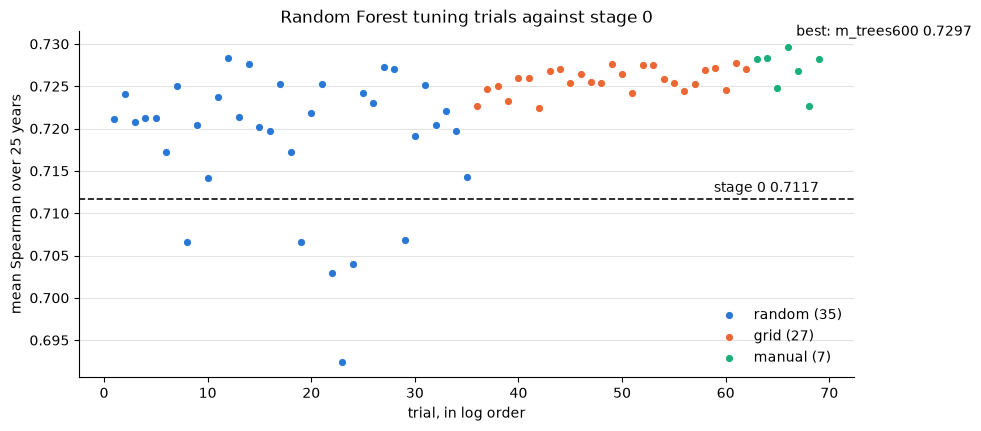

In [9]:
plot_trials(frame)  # chart 1: mean Spearman of every tuned trial with the stage 0 line

In [10]:
ad = rf_adoption(LOG)  # candidate against stage 0, computed from the logged yearly values
print('candidate:', ad['candidate']['trial'], '| adopted:', ad['adopted'])  # outcome of the rule
print('locked parameters:', ad['locked'])  # forest used from here on
display(conditions_table(ad['conditions']))  # the three adoption conditions with their numbers

candidate: m_trees600 | adopted: True
locked parameters: {'n_estimators': 600, 'max_depth': 13, 'min_samples_leaf': 7, 'max_features': 0.5, 'bootstrap': True, 'max_samples': 0.3253691715004556, 'random_state': 1}


,condition,holds,numbers
0,1 lower bound of paired bootstrap difference above 0,True,"(0.0179, 0.012, 0.0243)"
1,2 mean Spearman at least stage 0 in at least 4 of 5 tranches,True,5.0
2,3 mean top_10_styles not lower than stage 0,True,"(6.28, 6.16)"


In [11]:
stage0_gap = rf_overfit_table(panel, ad['stage0']['params'])  # train, validation and gap per year, stage 0
locked_gap = rf_overfit_table(panel, ad['locked'])  # same for the locked forest
print('largest difference of the locked validation column against its log row:', (locked_gap['validation'] - ad['candidate']['spearman']).abs().max())  # must be 0 up to rounding
display(pd.concat({'stage 0': rf_overfit_summary(stage0_gap), 'locked': rf_overfit_summary(locked_gap)}, axis=1).round(4))  # tranche, overall and worst-year values

largest difference of the locked validation column against its log row: 0.0


stage 0                     locked                   
                 train validation     gap   train validation     gap
1993-1997       0.7823     0.7565  0.0257  0.8122     0.7781  0.0341
1998-2002       0.7747     0.6766  0.0981  0.8100     0.6952  0.1148
2003-2007       0.7639     0.7148  0.0490  0.8030     0.7301  0.0729
2008-2012       0.7639     0.7581  0.0058  0.8035     0.7688  0.0347
2013-2017       0.7646     0.6525  0.1121  0.8029     0.6761  0.1268
overall         0.7699     0.7117  0.0582  0.8063     0.7297  0.0767
worst year gap  0.7752     0.6042  0.1711  0.8112     0.6337  0.1775

### Interpretation

The log has 70 trials. Stage 0 scores a mean Spearman of 0.7117. The random search (35 trials) ranges from 0.6924 to 0.7283 with a median of 0.7212, and 29 trials beat stage 0, the six that do not all having `max_depth` 3 or 4. The grid (27 trials) ranges from 0.7224 to 0.7277 and all 27 beat stage 0. Of the seven manual trials only `m_trees600` (+0.0014 against the base, trial 12) and `m_depth_none` (+0.00004) are above the base, while `m_nobootstrap` (-0.0056) and `m_leaf30` (-0.0035) are clearly below it, and the absolute error criterion changes nothing (-0.00007) at about six times the time. The chart shows a plateau between about 0.722 and 0.730 from the grid on. By the selection rule the candidate is `m_trees600` (mean Spearman 0.7297, top_10_styles 6.28), and its lead over trial 12 is far below the noise of the metric, so the choice is mechanical. Doubling the trees only reduces the variance of the forest.

The three adoption conditions hold: the Spearman difference against stage 0 is +0.0179 with a paired year-bootstrap interval of 0.0120 to 0.0243, the candidate is at least as good in 5 of 5 tranches, and its mean top_10_styles is 6.28 against 6.16. The locked forest is 600 trees, `max_depth` 13, `min_samples_leaf` 7, `max_features` 0.5, `max_samples` 0.3254, bootstrap on, seed 1.

The diagnostic shows a larger gap for the locked forest: the Spearman on its own training rows rises from 0.7699 to 0.8063 and on the target year from 0.7117 to 0.7297, so the gap grows from 0.0582 to 0.0767, and the worst single-year gap from 0.1711 to 0.1775. The validation score is higher in all five tranches. The gap is largest in 1998-2002 and 2013-2017 for both forests. The validation column equals the log row exactly.

### Decision

The candidate replaces stage 0 and the forest is locked. A deeper forest shows a larger gap by construction, and the adoption conditions already require the validation score to be higher, so overfitting is measured and not eliminated. The tuning families ccp_alpha, min_impurity_decrease, max_leaf_nodes and min_samples_split were not explored. The gain is measured on the same development years that selected it.

## 4. Pass rule with the locked forest

### Question: does the locked Random Forest pass the five conditions of the design entry on the development years?

The pass rule of the design entry is applied once more with the locked forest in place of the untuned one. BayesianRidge and XGBoost stay untuned and the baselines are unchanged. All methods are recomputed in one walk-forward run on the 25 development years. The candidate is the model with the highest mean top_10_styles and all five conditions must hold: (1) at least 0.5 above the best baseline, (2) at least as many as the best baseline in at least 15 of 25 years, (3) the lower bound of the paired year-bootstrap interval above 0, (4) at least 1.0 above the random expectation with the lower bound above 0, (5) mean Spearman not below that of the best baseline. If any fails, the recommended ranking is the best baseline.

In [12]:
results_locked = walk_forward_tuned(panel, LOCKED_RF_PARAMS)  # all methods, forest with the locked settings, development years only
print('forest equals the log row m_trees600 (top_10_styles and top_5_styles):', matches_log_row(results_locked, LOG, 'm_trees600'))  # forest check
print('baselines and untuned models equal the saved development values:', matches_saved_hits(results_locked, DEV_CSV, BASELINES + ['bayes_ridge', 'xgboost']))  # untuned check
hits10_locked, ci10 = hits_summary(results_locked, 10)  # top_10_styles per year and the mean with its interval
hits5_locked, ci5 = hits_summary(results_locked, 5)  # top_5_styles per year and the mean with its interval
display(pd.concat({'top_10_styles': ci10, 'top_5_styles': ci5}, axis=1).round(2))  # mean and 95% interval per method

forest equals the log row m_trees600 (top_10_styles and top_5_styles): True
baselines and untuned models equal the saved development values: True


top_10_styles             top_5_styles            
                       mean   low  high         mean   low  high
random                 0.54  0.52  0.57         0.14  0.13  0.14
repeat_last            6.00  5.48  6.52         2.72  2.28  3.12
mean_growth            4.52  4.00  5.04         1.96  1.48  2.40
bayes_ridge            6.12  5.52  6.72         2.72  2.36  3.08
xgboost                6.00  5.48  6.52         2.44  2.08  2.80
random_forest          6.28  5.80  6.84         2.76  2.40  3.12

In [13]:
spearman_locked = spearman_table(results_locked)  # Spearman per year on the styles scored by every method
print(spearman_locked[BASELINES + MODELS].mean().round(3).to_string())  # mean Spearman per method over the 25 years
rule = pass_rule(hits10_locked, spearman_locked)  # the five conditions of the design entry
print(f"candidate {rule['candidate']}, best baseline {rule['baseline']}")  # who is compared with whom
display(conditions_table(rule['conditions']))  # each condition with True or False and its numbers
print('recommended ranking:', rule['recommended'])  # outcome of the rule

repeat_last      0.707
mean_growth      0.550
bayes_ridge      0.695
xgboost          0.699
random_forest    0.730
candidate random_forest, best baseline repeat_last


,condition,holds,numbers
0,1 mean top_10_styles at least 0.5 above best baseline,False,0.28
1,2 at least as many hits as best baseline in 15+ years,True,21.0
2,3 lower bound of paired difference above 0,False,-0.12
3,4 at least 1.0 above random and lower bound above 0,True,"(5.737, 5.2461)"
4,5 mean Spearman not below best baseline,True,"(0.7297, 0.7069)"


recommended ranking: repeat_last


### Interpretation

With the locked forest the mean top_10_styles is 6.28 (interval 5.80 to 6.84) against 6.00 for repeat last year (5.48 to 6.52), a margin of 0.28. Two of the five conditions fail: the margin is below 0.5, and the lower bound of the paired year-bootstrap interval is -0.12. The other three hold: at least as many as repeat last year in 21 of 25 years, 5.74 above the random expectation with a lower bound of 5.25, and a mean Spearman of 0.7297 against 0.7069 for the best baseline. The forest orders the whole list better than repeat last year but is not shown better at its top 10.

### Decision

The pass rule fails, so the recommended ranking is repeat last year, as fixed in the design entry. The locked Random Forest, BayesianRidge and XGBoost stay available in the demo, labelled as validation results. The rule is not changed after seeing the result.

## 5. Final test, target years 2018 to 2022

### Question: do the locked Random Forest and the baselines score on the test years as printed by the test run?

The test years were scored once, with the same walk-forward procedure and settings as the development years, and no rule was applied there. Only the locked winner and the baselines (random, repeat last year, mean growth) are reported on the test years, as in the WHEN and WHAT holdouts; the other models were compared on the development years only. This section fits nothing. It reads the saved predictions, rebuilds the actual counts and the bases from the series, recomputes top_10_styles, top_5_styles, the Spearman, the count metrics and the paired differences, and compares them with the values printed in the console report of the test run (`results/style_forecast/test_20261015_173215.out`). A difference would be reported and the printed values would stay the reference.

In [14]:
pred = pd.read_csv(PRED_CSV)  # saved predictions of the test years and the 2024 projection, read only
test, checks = test_frame(pred, table, 2018, 2022)  # test years rebuilt from the series and the saved predictions, no fit
print(checks)  # consistency of the saved rows with the series
printed = read_printed_test(TEST_OUT)  # tables of the console report of the test run
compare_all(test, results_locked, printed)  # every printed quantity against its recomputed value

{'rows per year equal to the saved predictions': True, 'no missing saved value': True, 'saved repeat last score equals the series growth': True, 'saved expected Works equal base x exp(prediction)': True}


,quantity,max abs difference,within printed rounding
0,top_10_styles per year,0.004858,True
1,top_10_styles mean and interval,0.002752,True
2,top_5_styles per year,0.004603,True
3,top_5_styles mean and interval,0.004497,True
4,Spearman per year,0.000399,True
5,Spearman mean,0.000428,True
6,count metrics (median APE and coverage),0.000488,True
7,"paired differences, test years",0.000357,True
8,"paired differences, development years",0.000336,True
9,count rows in the same order,0.000000,True


In [15]:
per10_test, ci10_test = hits_summary(test, 10, TEST_METHODS)  # top_10_styles per test year and the mean with its interval, locked forest and baselines
per5_test, ci5_test = hits_summary(test, 5, TEST_METHODS)  # top_5_styles per test year and the mean with its interval, same methods
print('top_10_styles per test year')  # label
display(per10_test.round(2))  # per year
print('top_10_styles mean and 95% interval, recomputed next to printed')  # label
display(side_by_side(ci10_test, printed['hits10_mean'].loc[TEST_METHODS], 2))  # mean and interval
print('top_5_styles mean and 95% interval, recomputed next to printed')  # label
display(side_by_side(ci5_test, printed['hits5_mean'].loc[TEST_METHODS], 2))  # mean and interval

top_10_styles per test year


,eligible,random,repeat_last,mean_growth,random_forest
2018,230.0,0.43,3.0,2.0,6.0
2019,236.0,0.42,8.0,5.0,8.0
2020,239.0,0.42,6.0,4.0,5.0
2021,245.0,0.41,5.0,3.0,6.0
2022,247.0,0.40,5.0,6.0,5.0


top_10_styles mean and 95% interval, recomputed next to printed


recomputed             printed            
                    mean   low  high    mean   low  high
random              0.42  0.41  0.43    0.42  0.41  0.43
repeat_last         5.40  4.00  6.80    5.40  4.00  6.80
mean_growth         4.00  2.80  5.20    4.00  2.80  5.20
random_forest       6.00  5.20  7.00    6.00  5.20  7.00

top_5_styles mean and 95% interval, recomputed next to printed


recomputed            printed           
                    mean  low  high    mean  low  high
random               0.1  0.1  0.11     0.1  0.1  0.11
repeat_last          2.2  1.6  2.80     2.2  1.6  2.80
mean_growth          1.8  1.2  2.40     1.8  1.2  2.40
random_forest        2.6  2.0  3.40     2.6  2.0  3.40

In [16]:
metrics = keep_test_counts(count_metrics(test, test))  # count metrics from the saved ranges: all eligible styles and the forest's own top 10, forest and count baselines
shown_counts = keep_test_counts(printed['counts'])  # the same rows of the printed report
sp_test = spearman_table(test)  # Spearman per year on the common styles
print('count metrics, recomputed next to printed (median APE and coverage)')  # label
display(side_by_side(metrics.set_index(['set', 'method'])[['median_ape', 'coverage']], shown_counts.set_index(['set', 'method'])[['median_ape', 'coverage']], 3))  # count table
print('mean Spearman on the common styles, recomputed next to printed')  # label
display(side_by_side(sp_test[TEST_SCORED].mean().to_frame('mean'), printed['spearman_mean'].loc[TEST_SCORED].to_frame('mean'), 3))  # mean Spearman
print('descriptive paired differences on the test years (forest minus repeat last year), recomputed next to printed')  # label
display(side_by_side(forest_rows(paired_differences(test)), forest_rows(printed['paired_test']), 3))  # paired differences
print('descriptive paired differences on the development years (locked forest), recomputed next to printed')  # label
display(side_by_side(forest_rows(paired_differences(results_locked)), forest_rows(printed['paired_dev']), 3))  # paired differences

count metrics, recomputed next to printed (median APE and coverage)


recomputed             printed         
                                      median_ape coverage median_ape coverage
set                     method                                               
all eligible            random_forest      0.101    0.728      0.101    0.728
                        repeat_ct          0.100    0.742      0.100    0.742
                        mean3              0.125    0.789      0.125    0.789
top 10 of random_forest random_forest      0.178    0.480      0.178    0.480
                        repeat_ct          0.188    0.440      0.188    0.440
                        mean3              0.392    0.280      0.392    0.280

mean Spearman on the common styles, recomputed next to printed


,recomputed,printed
,mean,mean
repeat_last,0.578,0.578
mean_growth,0.452,0.452
random_forest,0.597,0.597


descriptive paired differences on the test years (forest minus repeat last year), recomputed next to printed


recomputed               printed              
                                  mean    low   high    mean    low   high
random_forest top_10_styles      0.600 -0.400  1.800   0.600 -0.400  1.800
random_forest Spearman           0.019  0.001  0.038   0.019  0.001  0.038

descriptive paired differences on the development years (locked forest), recomputed next to printed


recomputed               printed              
                                  mean    low   high    mean    low   high
random_forest top_10_styles      0.280 -0.120  0.680   0.280 -0.120  0.680
random_forest Spearman           0.023  0.013  0.033   0.023  0.013  0.033

In [17]:
dev_metrics = count_metrics(count_table(results_locked), results_locked)  # development count metrics with the locked forest, for the coverage comparison
dev_metrics[(dev_metrics['set'] == 'all eligible') | (dev_metrics['set'] == 'top 10 of ' + dev_metrics['method'])].round(3)  # all eligible styles and each model's own top 10

,set,method,n,median_ape,coverage
0,all eligible,bayes_ridge,4545,0.087,0.835
1,all eligible,xgboost,4545,0.086,0.845
2,all eligible,random_forest,4545,0.081,0.837
3,all eligible,repeat_ct,4545,0.088,0.835
4,all eligible,mean3,4545,0.128,0.841
5,top 10 of bayes_ridge,bayes_ridge,240,0.153,0.621
11,top 10 of xgboost,xgboost,240,0.152,0.629
17,top 10 of random_forest,random_forest,240,0.128,0.642


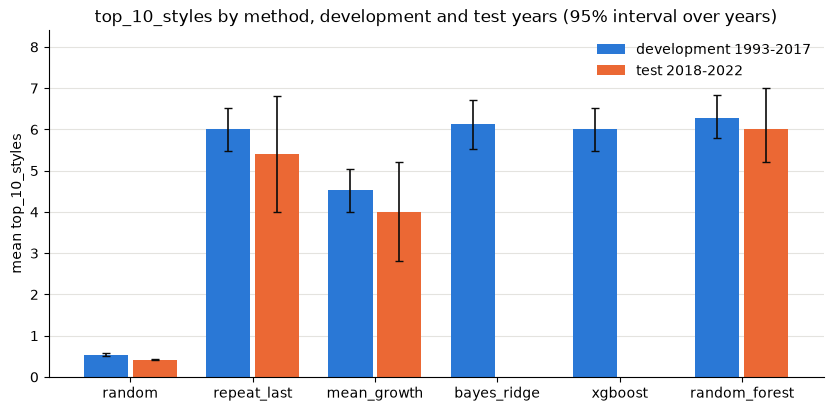

In [18]:
plot_hits(ci10, ci10_test)  # chart 2: mean top_10_styles on development (all methods, locked forest) and test years (locked forest and baselines)

### Interpretation

Every printed quantity of the reported methods is reproduced by the recomputation from the saved predictions and the series, with the largest difference inside the rounding of the printed digits (at most 0.0049 for top_10_styles and top_5_styles, 0.0004 for the Spearman, the count metrics and the paired differences), and the saved rows agree with the series (same eligible styles, same growth, same base). The printed values stay the reference.

On the test years the mean top_10_styles is 6.00 for Random Forest (interval 5.20 to 7.00), 5.40 for repeat last year (4.00 to 6.80), 4.00 for the mean growth and 0.42 at random. With 5 years the intervals are wide and overlap. The mean Spearman is 0.597 for Random Forest, 0.578 for repeat last year and 0.452 for the mean growth. The paired difference of the forest against repeat last year is +0.60 top_10_styles (interval -0.40 to 1.80) and +0.019 Spearman (0.001 to 0.038) on the test years, against +0.28 (-0.12 to 0.68) and +0.023 (0.013 to 0.033) on the development years.

Over all eligible styles the median absolute percentage error is 0.101 for the forest and 0.100 for repeating last year's count, and the range coverage of the forest is 0.728 on the test years against 0.837 on the development years (nominal 0.80). Over the forest's own predicted top 10 the coverage is 0.48 on the test years against 0.642 on the development years.

### Decision

No rule is applied on the test years and nothing is changed after seeing them. The test agrees with the development result: the forest orders the whole list better (the Spearman interval stays above 0) and is not shown better at the top 10 (the top_10_styles interval includes 0), so the recommended ranking stays repeat last year. The ranges of the predicted top 10 under-cover on both sets and this is reported, not corrected.

## 6. Projection for 2024

### Question: which styles does the recommended ranking put in the top 10 for 2024, and how large are the bases behind their growth?

The ranking is repeat last year (growth of 2023 over the mean of 2020 to 2022). The three models are fitted on origins up to 2022 with the locked parameters and predict from origin 2023. The growth base is the mean of 2020 to 2022 and is computed here from the series, since the growth of 2023 equals the Works of 2023 over one plus growth over that base. The expected Works of 2024 use a different base, the mean of 2021 to 2023. A style whose growth base is below 100 is flagged: it is eligible for 2024 through its 2021 to 2023 base, but its growth was measured on a small denominator.

In [19]:
top10 = projection_table(pred, table, 2023)  # top 10 by repeat last year with both bases computed from the series
print('Works of 2023 over (1 + growth) equals the series growth base for all ten:', top10['growth_check'].all())  # check of the saved growth
top10[['style', 'growth', 'works', 'growth_base', 'expected_base', 'flag']].round(3)  # growth, Works of 2023, both bases and the small-denominator flag

Works of 2023 over (1 + growth) equals the series growth base for all ten: True


,style,growth,works,growth_base,expected_base,flag
0,Noise Rock,3.649,468,100.667,230.000,False
1,Dark Electro,3.204,412,98.000,218.333,True
2,Alternative Metal,3.098,403,98.333,211.000,True
3,Plunderphonics,2.298,443,134.333,267.667,False
4,Alt-Pop,2.037,892,293.667,532.667,False
5,Future House,1.894,436,150.667,251.667,False
6,Balearic,1.407,272,113.000,192.667,False
7,Bass Music,1.050,708,345.333,459.000,False
8,Latin Pop,0.951,173,88.667,116.667,True
9,Latin,0.923,398,207.000,290.000,False


In [20]:
top10[['style'] + MODELS]  # expected Works of 2024 and 10th to 90th percentile range of the three models

,style,bayes_ridge,xgboost,random_forest
0,Noise Rock,723 (601-881),373 (306-450),475 (400-573)
1,Dark Electro,570 (474-694),571 (468-689),446 (376-538)
2,Alternative Metal,574 (478-700),458 (376-553),486 (409-585)
3,Plunderphonics,564 (469-687),483 (396-582),506 (426-609)
4,Alt-Pop,1094 (910-1333),1050 (861-1267),1053 (888-1269)
5,Future House,568 (472-692),347 (285-419),376 (317-453)
6,Balearic,319 (266-389),186 (152-224),246 (208-297)
7,Bass Music,837 (696-1020),621 (509-749),643 (542-775)
8,Latin Pop,196 (163-239),195 (160-236),180 (152-217)
9,Latin,437 (363-532),456 (374-550),454 (383-547)


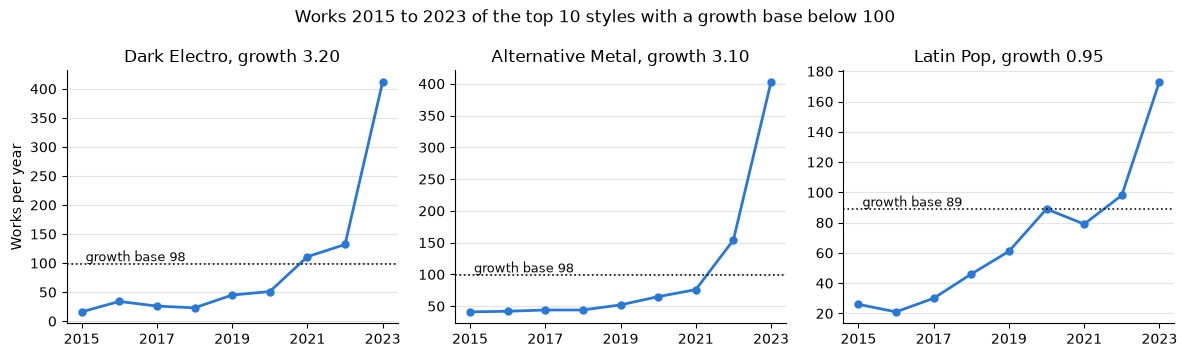

In [21]:
plot_flagged_works(table, top10, 2023)  # chart 3: Works 2015 to 2023 of the top 10 styles whose growth base is below 100

### Interpretation

For all ten styles the Works of 2023 over one plus growth equals the growth base computed from the series, so the saved growth is consistent with the counts. Three of the ten are flagged because the mean of 2020 to 2022 is below 100: Dark Electro (98.0, growth 3.204), Alternative Metal (98.3, growth 3.098) and Latin Pop (88.7, growth 0.951). Noise Rock is just above the level (100.7). The chart shows why: their counts stayed low until 2022 (2020 to 2022: 51, 111 and 132 Works for Dark Electro, 65, 76 and 154 for Alternative Metal, 89, 79 and 98 for Latin Pop) and then jumped in 2023 (412, 403 and 173), so a large part of their growth comes from a small denominator. All ten are eligible for 2024 through their 2021 to 2023 base, which is 211 or more for Dark Electro and Alternative Metal and 116.7 for Latin Pop. The three models disagree most on the largest spikes: for Noise Rock the expected Works of 2024 are 723 (BayesianRidge), 373 (XGBoost) and 475 (Random Forest), for Future House 568, 347 and 376, and for Balearic 319, 186 and 246.

### Decision

The flagged styles stay in the list with the flag and the small-denominator limit is reported, not corrected. The projection is illustrative: the counts are Works catalogued in Discogs and are expressed at the 2023 loading level, the 2023 spikes are not explained, the three models disagree on the largest spikes, the ranges of the predicted top 10 under-cover (coverage of each model's own top 10 is 0.62 to 0.64 on the development years and 0.48 for the forest on the test years, against 0.80 nominal), and no truth exists for 2024.

## 7. Summary and limitations

**Recommended ranking:** repeat last year. The locked Random Forest (600 trees, `max_depth` 13, `min_samples_leaf` 7, `max_features` 0.5, `max_samples` 0.3254) orders the whole list better than repeat last year, with a mean Spearman difference of +0.023 on the development years and +0.019 on the test years and both intervals above 0. It is not shown better at the top 10: the top_10_styles difference is +0.28 on the development years and +0.60 on the test years with both intervals including 0, and the pass rule fails on two of five conditions (margin 0.28 below 0.5, lower bound -0.12). BayesianRidge and XGBoost are not shown better than repeat last year on the development years, where all models were compared, and are not reported on the test years.

**Limitations**

- The ranges of the predicted top 10 under-cover (coverage of each model's own top 10 is 0.62 to 0.64 on the development years and 0.48 for the forest on the test years, against 0.80 nominal) because the residual quantiles pool all eligible styles.
- The test has 5 years, so its intervals are wide.
- The tuned gain is measured on the same development years that selected it, and the adoption bootstrap resamples years only.
- The selection metric (Spearman over the whole list) differs from the decision metric (top_10_styles).
- The tuning families ccp_alpha, min_impurity_decrease, max_leaf_nodes and min_samples_split were not explored.
- The counts are Works catalogued in Discogs, not sales or listens, and the 2023 level is not explained.
- A top 10 style can enter through a small growth base (three of the ten styles of the 2024 projection).

**What the demo can read:** `results/style_forecast/predictions.csv` holds one row per style, target year and method (`bayes_ridge`, `xgboost`, `random_forest`, `repeat_last`) with `expected_growth`, `expected_works`, `range_low`, `range_high` and `rank`, for the test years 2018 to 2022 and the projection for 2024 (rows per year and method below). The test rows of the two untuned models exist in the file but are not used in any decision and not reported. `results/style_forecast/models/` holds one fitted file per model (`bayes_ridge`, `xgboost`, `random_forest`), each a dictionary with the model, its input columns and the scaling statistics (only for BayesianRidge), fitted on origins up to 2022. The demo only reads these files and writes nothing.

In [22]:
pred.groupby(['target_year', 'method']).size().unstack()  # rows saved per target year and method (2024 is the projection)

method,bayes_ridge,random_forest,repeat_last,xgboost
target_year,,,,
2018,230,230,230,230
2019,236,236,236,236
2020,239,239,239,239
2021,245,245,245,245
2022,247,247,247,247
2024,247,247,247,247
